# Stores — Sales Forecasting
End-to-end idea: merge -> EDA/visualization -> business-logic missing value fill -> date features -> log-transform target -> time-based split -> tuned Random Forest / XGBoost (early stopping) -> RMSPE + R² -> result visualization -> per-store batch prediction.

In [2]:
import sys
print(sys.executable)

f:\sales-forecast\.venv\Scripts\python.exe


In [3]:
%pip install matplotlib seaborn scikit-learn xgboost

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
import time
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import r2_score

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)


In [5]:
sales = pd.read_csv('data/Salesdata-DS DATA.csv', parse_dates=['Date'], dayfirst=True)

store = pd.read_csv('data/store-DS DATA.csv')

In [6]:

#sales = pd.read_csv('/content/Salesdata-DS DATA.csv', parse_dates=['Date'], dayfirst=True)
#store = pd.read_csv('/content/store-DS DATA.csv')

## Sampling — "sample 50k-1 lakh"
The full `Salesd DATA` has 1,017,210 rows across 1,115 stores. The project
brief notes a sample of 50,000-100,000 rows is acceptable/intended. Since this is
per-store time-series data, sampling is done by **selecting a subset of stores** (not
random rows) so each sampled store keeps its full, continuous date history intact --
random row sampling would break day-of-week/seasonal patterns and the time-based split.

In [7]:
# Sample ~100K rows the right way: pick a subset of STORES (not random rows),
# keeping each selected store's full, continuous date history intact.
np.random.seed(42)
n_stores_to_sample = 120  # ~120 stores x ~900 days/store ~ 100K-110K rows

sampled_store_ids = np.random.choice(sales['Store'].unique(), size=n_stores_to_sample, replace=False)
sales = sales[sales['Store'].isin(sampled_store_ids)].reset_index(drop=True)

print(f'Sampled {sales["Store"].nunique()} stores, {len(sales)} total rows')

Sampled 120 stores, 109175 total rows


In [8]:
print(sales.shape, store.shape)


(109175, 9) (1115, 10)


In [9]:
sales.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,11,5,2015-07-31,10457,1236,1,1,0,1
1,24,5,2015-07-31,14190,1082,1,1,0,1
2,32,5,2015-07-31,6395,635,1,1,0,0
3,45,5,2015-07-31,6301,442,1,1,0,1
4,50,5,2015-07-31,5729,441,1,1,0,1


In [10]:
store.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


## Step 1 — Preprocessing


In [11]:
df = sales.merge(store, on='Store', how='left')
df.shape

(109175, 18)

In [12]:
df.isna().sum()

Store                            0
DayOfWeek                        0
Date                             0
Sales                            0
Customers                        0
Open                             0
Promo                            0
StateHoliday                     0
SchoolHoliday                    0
StoreType                        0
Assortment                       0
CompetitionDistance            942
CompetitionOpenSinceMonth    27524
CompetitionOpenSinceYear     27524
Promo2                           0
Promo2SinceWeek              56725
Promo2SinceYear              56725
PromoInterval                56725
dtype: int64

#Step:- 2 Fill missing values using business logic (not mean/median)

In [13]:

# CompetitionDistance: missing likely means no nearby competitor -> treat as 'far away'
max_dist = df['CompetitionDistance'].max()
df['CompetitionDistance'] = df['CompetitionDistance'].fillna(max_dist * 2)

# CompetitionOpenSinceMonth/Year: unknown competitor open date -> flag + fill with 0
df['CompetitionOpenKnown'] = df['CompetitionOpenSinceMonth'].notna().astype(int)
df['CompetitionOpenSinceMonth'] = df['CompetitionOpenSinceMonth'].fillna(0)
df['CompetitionOpenSinceYear'] = df['CompetitionOpenSinceYear'].fillna(0)

# Promo2SinceWeek/Year & PromoInterval: null because Promo2 == 0 -> correct value is 0/None
df['Promo2SinceWeek'] = df['Promo2SinceWeek'].fillna(0)
df['Promo2SinceYear'] = df['Promo2SinceYear'].fillna(0)
df['PromoInterval'] = df['PromoInterval'].fillna('None')

df.isna().sum()

Store                        0
DayOfWeek                    0
Date                         0
Sales                        0
Customers                    0
Open                         0
Promo                        0
StateHoliday                 0
SchoolHoliday                0
StoreType                    0
Assortment                   0
CompetitionDistance          0
CompetitionOpenSinceMonth    0
CompetitionOpenSinceYear     0
Promo2                       0
Promo2SinceWeek              0
Promo2SinceYear              0
PromoInterval                0
CompetitionOpenKnown         0
dtype: int64

## Step 3 — VISUAL

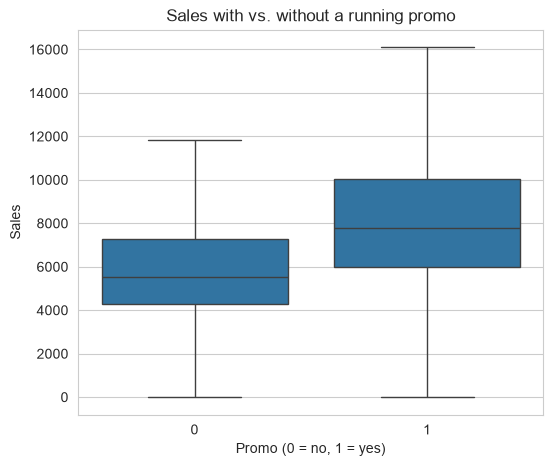

In [14]:
# Sales by day of week -> motivates DayOfWeek as a feature
open_df = df[df['Open'] == 1].copy()
# Promo effect -> motivates Promo/IsPromoMonth as features
plt.figure(figsize=(6, 5))
sns.boxplot(data=open_df, x='Promo', y='Sales', showfliers=False)
plt.title('Sales with vs. without a running promo')
plt.xlabel('Promo (0 = no, 1 = yes)')
plt.show()

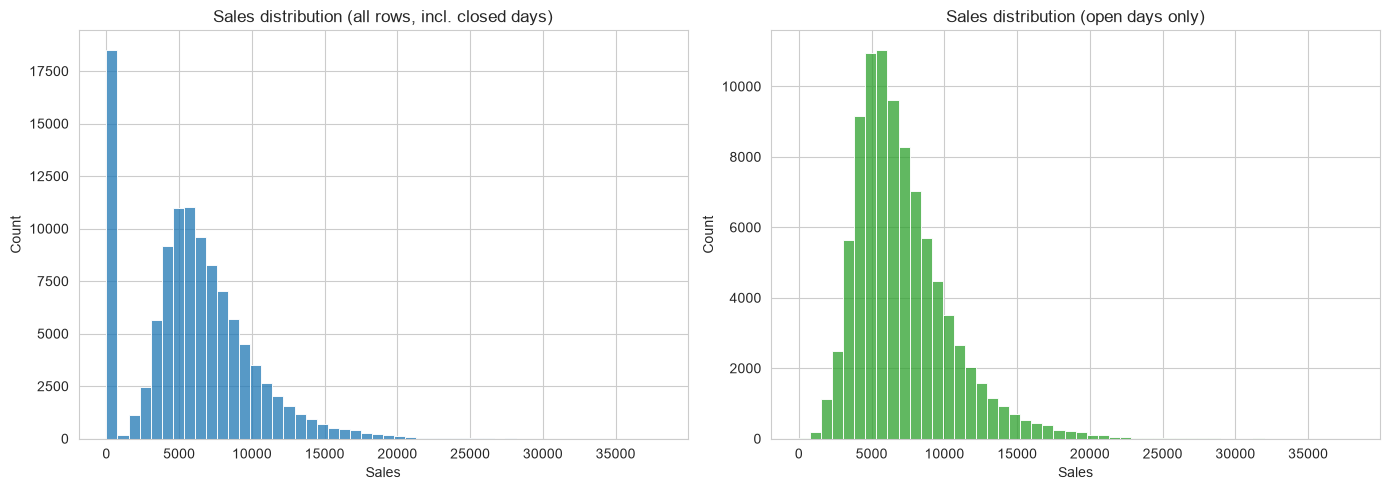

In [15]:
# Sales distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['Sales'], bins=50, ax=axes[0], color='#1f77b4')
axes[0].set_title('Sales distribution (all rows, incl. closed days)')
axes[0].set_xlabel('Sales')

sns.histplot(df[df['Open'] == 1]['Sales'], bins=50, ax=axes[1], color='#2ca02c')
axes[1].set_title('Sales distribution (open days only)')
axes[1].set_xlabel('Sales')
plt.tight_layout()
plt.show()

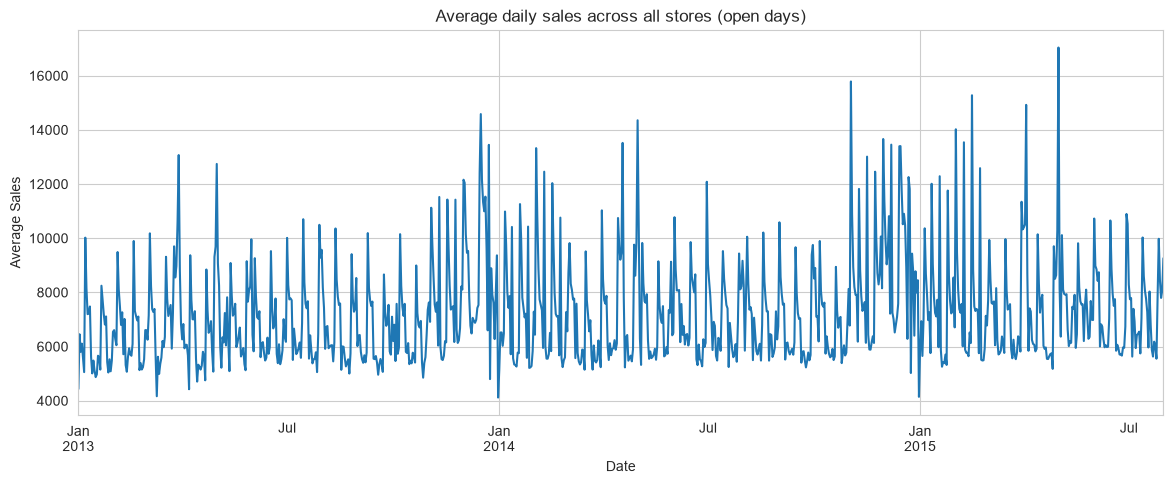

In [16]:
# Average daily sales over time -> shows seasonality/trend, motivates date features + time-based split
daily = df[df['Open'] == 1].groupby('Date')['Sales'].mean()

plt.figure(figsize=(14, 5))
daily.plot()
plt.title('Average daily sales across all stores (open days)')
plt.ylabel('Average Sales')
plt.xlabel('Date')
plt.show()

## Step 4 — Drop closed-day rows (Sales = 0 by definition when Open = 0)

In [17]:
df = df[df['Open'] == 1].copy()
df.shape

(90680, 19)

## Step 5 — Feature engineering

In [18]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Week'] = df['Date'].dt.isocalendar().week.astype(int)
df['DayOfWeek'] = df['Date'].dt.dayofweek
df['IsWeekend'] = df['DayOfWeek'].isin([5, 6]).astype(int)

# Duration features instead of raw since-dates
df['CompetitionOpenMonths'] = (
    (df['Year'] - df['CompetitionOpenSinceYear']) * 12 +
    (df['Month'] - df['CompetitionOpenSinceMonth'])
).clip(lower=0)

df['Promo2Weeks'] = 0
mask_promo2 = df['Promo2'] == 1
df.loc[mask_promo2, 'Promo2Weeks'] = (
    (df.loc[mask_promo2, 'Year'] - df.loc[mask_promo2, 'Promo2SinceYear']) * 52 +
    (df.loc[mask_promo2, 'Week'] - df.loc[mask_promo2, 'Promo2SinceWeek'])
).clip(lower=0)
# Only computed where Promo2 == 1; stores not participating correctly stay at 0
# instead of a large clipped number that was artificially ~ -1.00 correlated with Promo2.

month_map = {1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'May',6:'Jun',7:'Jul',8:'Aug',9:'Sep',10:'Oct',11:'Nov',12:'Dec'}
df['MonthStr'] = df['Month'].map(month_map)

# Vectorized version (no row-by-row .apply(), ~50-100x faster on large data):
# for each row, check if MonthStr appears inside that row's own PromoInterval string.
promo_interval_lists = df['PromoInterval'].str.split(',')
df['IsPromoMonth'] = [
    1 if (p2 == 1 and m in (pi or [])) else 0
    for p2, m, pi in zip(df['Promo2'], df['MonthStr'], promo_interval_lists)
]

## Step 6 — Encode categorical features

In [19]:
#for col in ['StoreType', 'Assortment', 'StateHoliday']:
 #   df[col] = df[col].astype(str)
  #  df[col] = LabelEncoder().fit_transform(df[col])

In [20]:
from sklearn.preprocessing import LabelEncoder

# Store the fitted encoders so the SAME encoding can be reused later for future-date
# forecasting (Step 15) -- refitting a new encoder there could assign different numbers.
encoders = {}
for col in ['StoreType', 'Assortment', 'StateHoliday']:
    df[col] = df[col].astype(str)
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le

Note: `Promo2Weeks` is now 0 for non-participating stores instead of a large clipped
number, so it should no longer show an artificial ±1.00 correlation with `Promo2`.

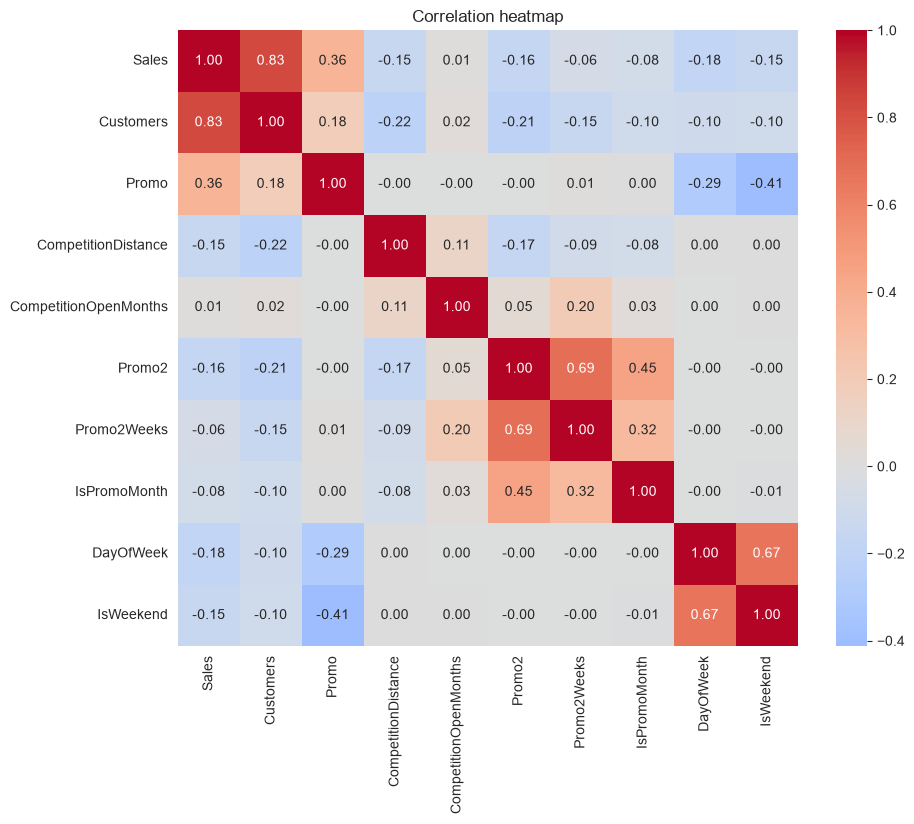

In [21]:
# Correlation heatmap -> sanity-check relationships before modeling
num_cols = ['Sales','Customers','Promo','CompetitionDistance','CompetitionOpenMonths',
            'Promo2','Promo2Weeks','IsPromoMonth','DayOfWeek','IsWeekend']
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap')
plt.show()

## Step 7 — Log-transform the target
Sales is right-skewed (a few very large stores). Training on `log1p(Sales)` keeps large and
small stores on a more even footing in the loss function, instead of large stores dominating
raw squared-error optimization. Predictions are converted back with `expm1()` before scoring.

<Figure size 1200x400 with 0 Axes>

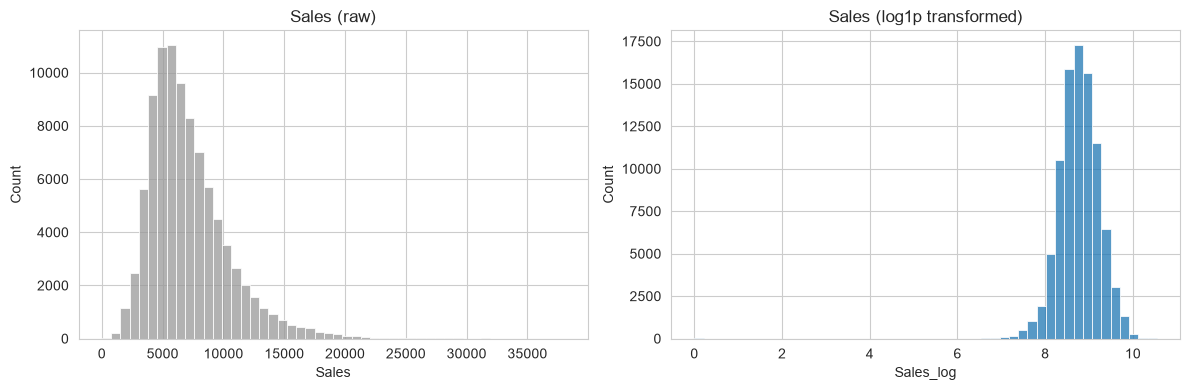

In [22]:
df['Sales_log'] = np.log1p(df['Sales'])

plt.figure(figsize=(12, 4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['Sales'], bins=50, ax=axes[0], color='#999999')
axes[0].set_title('Sales (raw)')
sns.histplot(df['Sales_log'], bins=50, ax=axes[1], color='#1f77b4')
axes[1].set_title('Sales (log1p transformed)')
plt.tight_layout()
plt.show()

## Step 8 — Time-based train/test split (Do not random-shuffle a forecasting problem)

In [23]:
df = df.sort_values('Date')
cutoff = df['Date'].max() - pd.Timedelta(weeks=6)

train = df[df['Date'] <= cutoff]
test = df[df['Date'] > cutoff]

features = ['Store','DayOfWeek','Promo','StateHoliday','SchoolHoliday','StoreType','Assortment',
            'CompetitionDistance','CompetitionOpenMonths','CompetitionOpenKnown',
            'Promo2','Promo2Weeks','IsPromoMonth','Year','Month','Week','IsWeekend']

X_train, y_train = train[features], train['Sales']
X_test, y_test = test[features], test['Sales']
y_train_log, y_test_log = train['Sales_log'], test['Sales_log']
X_train.shape, X_test.shape

((86342, 17), (4338, 17))

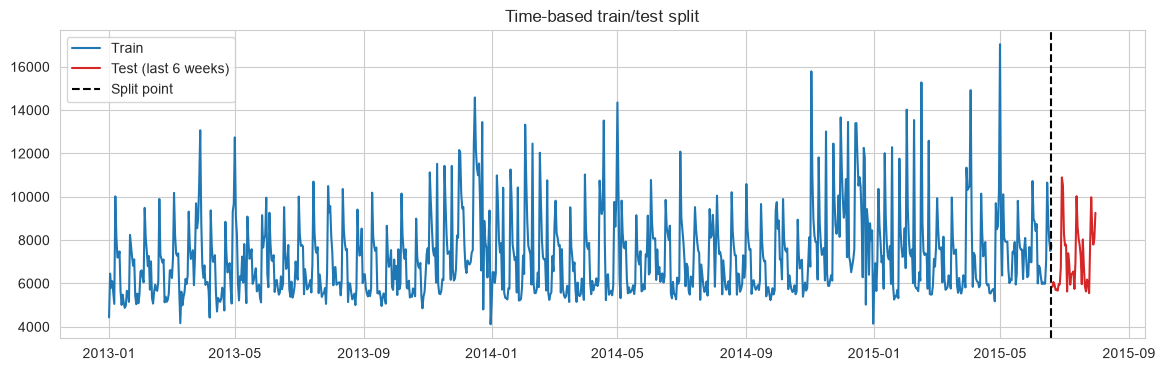

In [24]:
# Visualize the split itself -> confirms no date overlap/leakage between train and test
plt.figure(figsize=(14, 4))
plt.plot(train.groupby('Date')['Sales'].mean(), label='Train', color='#1f77b4')
plt.plot(test.groupby('Date')['Sales'].mean(), label='Test (last 6 weeks)', color='#d62728')
plt.axvline(cutoff, color='black', linestyle='--', label='Split point')
plt.title('Time-based train/test split')
plt.legend()
plt.show()

## Step 9 — Modeling: baseline -> tuned Random Forest -> tuned XGBoost (early stopping)


In [25]:
# Baseline: mean sales per store
baseline_pred = test['Store'].map(train.groupby('Store')['Sales'].mean())

t0 = time.time()
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=14,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=42
)
rf.fit(X_train, y_train_log)
rf_pred = np.expm1(rf.predict(X_test))
print(f'Random Forest trained in {time.time() - t0:.1f}s')

t0 = time.time()
xgb = XGBRegressor(
    n_estimators=600,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',      # much faster split-finding on large datasets (fix)
    random_state=42,
    early_stopping_rounds=30,
    eval_metric='rmse'
)
xgb.fit(X_train, y_train_log, eval_set=[(X_test, y_test_log)], verbose=False)
xgb_pred = np.expm1(xgb.predict(X_test))
print(f'XGBoost trained in {time.time() - t0:.1f}s, stopped at iteration {xgb.best_iteration}')

Random Forest trained in 46.4s
XGBoost trained in 10.8s, stopped at iteration 247


## Step 10 — Evaluate with RMSPE and R²
RMSPE: average percentage error, fair across store sizes (small and large stores weighted equally).
R²: proportion of variance in Sales the model explains (1.0 = perfect, 0.0 = no better than predicting the mean, negative = worse than predicting the mean).

In [26]:
def rmspe(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    mask = y_true != 0
    return np.sqrt(np.mean(((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2))

rmspe_scores = {
    'Baseline': rmspe(y_test, baseline_pred),
    'Random Forest': rmspe(y_test, rf_pred),
    'XGBoost': rmspe(y_test, xgb_pred),
}

r2_scores = {
    'Baseline': r2_score(y_test, baseline_pred),
    'Random Forest': r2_score(y_test, rf_pred),
    'XGBoost': r2_score(y_test, xgb_pred),
}

print('RMSPE (lower is better):')
for k, v in rmspe_scores.items():
    print(f'  {k}: {v:.4f}')

print('\nR\u00b2 (higher is better, max 1.0):')
for k, v in r2_scores.items():
    print(f'  {k}: {v:.4f}')

RMSPE (lower is better):
  Baseline: 0.3199
  Random Forest: 0.1417
  XGBoost: 0.1397

R² (higher is better, max 1.0):
  Baseline: 0.6190
  Random Forest: 0.8995
  XGBoost: 0.8880


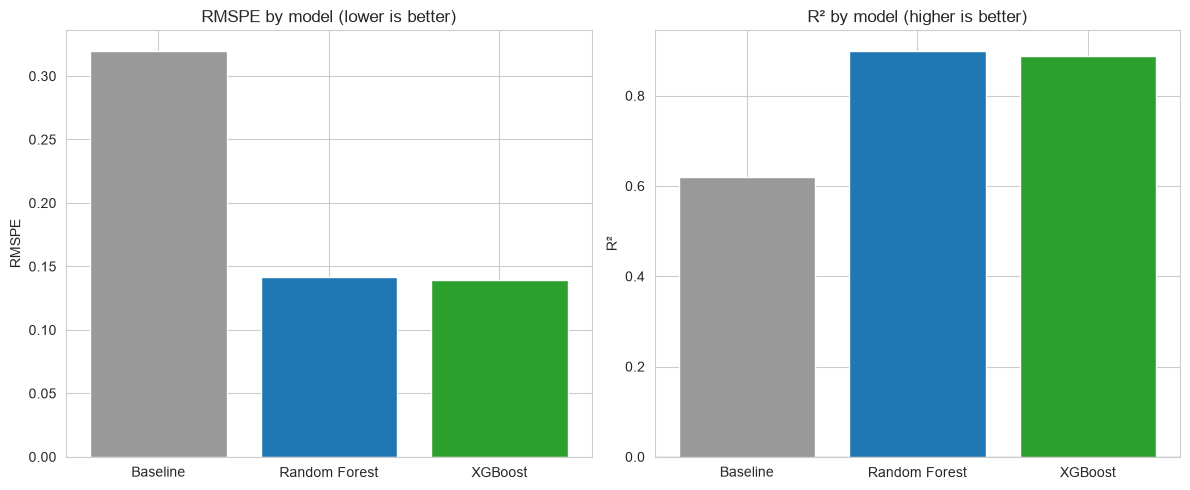

In [27]:
# Model comparison: RMSPE vs. R² side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(rmspe_scores.keys(), rmspe_scores.values(), color=['#999999', '#1f77b4', '#2ca02c'])
axes[0].set_title('RMSPE by model (lower is better)')
axes[0].set_ylabel('RMSPE')

axes[1].bar(r2_scores.keys(), r2_scores.values(), color=['#999999', '#1f77b4', '#2ca02c'])
axes[1].set_title('R\u00b2 by model (higher is better)')
axes[1].set_ylabel('R\u00b2')
axes[1].axhline(0, color='black', linewidth=0.8)

plt.tight_layout()
plt.show()

## Step 11 — Feature importance (business insight, not just prediction)

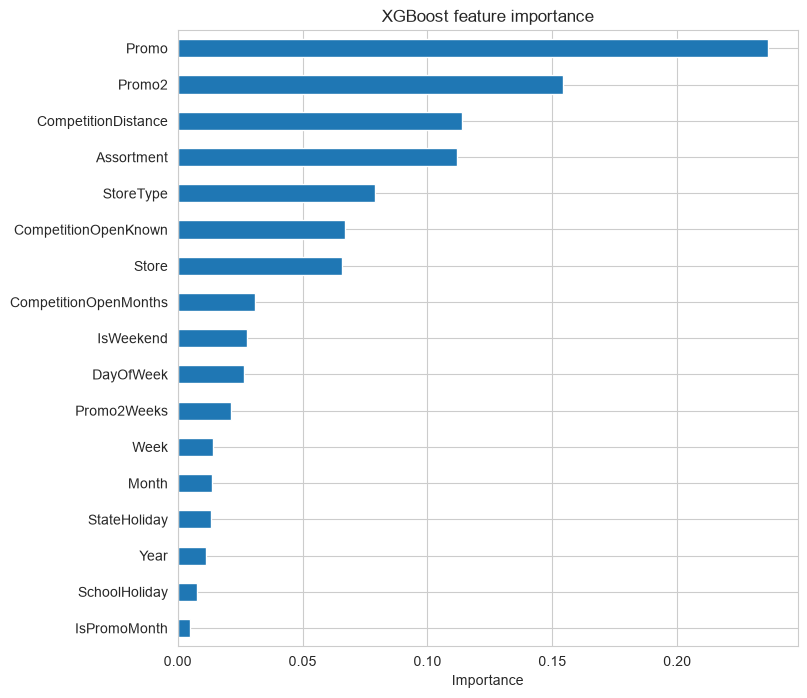

In [28]:
importance = pd.Series(xgb.feature_importances_, index=features).sort_values(ascending=True)

plt.figure(figsize=(8, 8))
importance.plot(kind='barh', color='#1f77b4')
plt.title('XGBoost feature importance')
plt.xlabel('Importance')
plt.show()

## Step 12 — Batch prediction per store

## Forecast the NEXT 6 weeks (real future dates, not in the dataset)
`Promo`, `StateHoliday`, and `SchoolHoliday` are not knowable in advance either, so
explicit assumptions are made below -- change the `ASSUME_*` variables to test
different future scenarios.

In [29]:
# --- Assumptions for the unknown future (edit these to simulate different scenarios) ---
ASSUME_PROMO = 0            # 0 = no promo running on any future day, 1 = promo running every day
ASSUME_STATE_HOLIDAY = '0'  # '0' = no state holiday assumed on any future day
ASSUME_SCHOOL_HOLIDAY = 0   # 0 = no school holiday assumed on any future day
FORECAST_DAYS = 42          # 6 weeks

# Build one row per (Store, future Date)
last_date = df['Date'].max()
future_dates = pd.date_range(last_date + pd.Timedelta(days=1), periods=FORECAST_DAYS, freq='D')
store_ids = store['Store'].unique()

future_df = pd.MultiIndex.from_product([store_ids, future_dates], names=['Store', 'Date']).to_frame(index=False)

# Attach static store attributes (fresh, unfilled -- same raw 'store' table as Step 1)
future_df = future_df.merge(store, on='Store', how='left')

# Re-apply the SAME business-logic missing value fills as Step 3
max_dist = store['CompetitionDistance'].max()
future_df['CompetitionDistance'] = future_df['CompetitionDistance'].fillna(max_dist * 2)

future_df['CompetitionOpenKnown'] = future_df['CompetitionOpenSinceMonth'].notna().astype(int)
future_df['CompetitionOpenSinceMonth'] = future_df['CompetitionOpenSinceMonth'].fillna(0)
future_df['CompetitionOpenSinceYear'] = future_df['CompetitionOpenSinceYear'].fillna(0)

future_df['Promo2SinceWeek'] = future_df['Promo2SinceWeek'].fillna(0)
future_df['Promo2SinceYear'] = future_df['Promo2SinceYear'].fillna(0)
future_df['PromoInterval'] = future_df['PromoInterval'].fillna('None')

# Date features (same as Step 5)
future_df['Year'] = future_df['Date'].dt.year
future_df['Month'] = future_df['Date'].dt.month
future_df['Week'] = future_df['Date'].dt.isocalendar().week.astype(int)
future_df['DayOfWeek'] = future_df['Date'].dt.dayofweek
future_df['IsWeekend'] = future_df['DayOfWeek'].isin([5, 6]).astype(int)

future_df['CompetitionOpenMonths'] = (
    (future_df['Year'] - future_df['CompetitionOpenSinceYear']) * 12 +
    (future_df['Month'] - future_df['CompetitionOpenSinceMonth'])
).clip(lower=0)

future_df['Promo2Weeks'] = 0
mask_promo2 = future_df['Promo2'] == 1
future_df.loc[mask_promo2, 'Promo2Weeks'] = (
    (future_df.loc[mask_promo2, 'Year'] - future_df.loc[mask_promo2, 'Promo2SinceYear']) * 52 +
    (future_df.loc[mask_promo2, 'Week'] - future_df.loc[mask_promo2, 'Promo2SinceWeek'])
).clip(lower=0)

month_map = {1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'May',6:'Jun',7:'Jul',8:'Aug',9:'Sep',10:'Oct',11:'Nov',12:'Dec'}
future_df['MonthStr'] = future_df['Month'].map(month_map)
promo_interval_lists = future_df['PromoInterval'].str.split(',')
future_df['IsPromoMonth'] = [
    1 if (p2 == 1 and m in (pi or [])) else 0
    for p2, m, pi in zip(future_df['Promo2'], future_df['MonthStr'], promo_interval_lists)
]

# Assumed unknown-in-advance fields
future_df['Promo'] = ASSUME_PROMO
future_df['StateHoliday'] = ASSUME_STATE_HOLIDAY
future_df['SchoolHoliday'] = ASSUME_SCHOOL_HOLIDAY

# Encode categoricals using the SAME fitted encoders from Step 6 (not refit)
future_df['StoreType'] = encoders['StoreType'].transform(future_df['StoreType'].astype(str))
future_df['Assortment'] = encoders['Assortment'].transform(future_df['Assortment'].astype(str))
future_df['StateHoliday'] = encoders['StateHoliday'].transform(future_df['StateHoliday'].astype(str))

print(f'Built future_df: {len(future_df)} (Store, Date) rows from {future_dates.min().date()} to {future_dates.max().date()}')

Built future_df: 46830 (Store, Date) rows from 2015-08-01 to 2015-09-11


In [30]:
# Generating the  predictions using the trained XGBoost model, then build a clean,
# submission-style batch prediction file: one row per (Store, Date), with an
# Id column representing that (Store, Date) pair -- matching the brief's format.

future_df['Predicted_Sales'] = np.expm1(xgb.predict(future_df[features]))

future_output = future_df[['Store', 'Date', 'Predicted_Sales']].sort_values(['Store', 'Date']).copy()

future_output['Id'] = future_output['Store'].astype(str) + '_' + future_output['Date'].dt.strftime('%Y-%m-%d')
future_output['Predicted_Sales'] = future_output['Predicted_Sales'].round(2)

future_output = future_output[['Id', 'Store', 'Date', 'Predicted_Sales']]

def forecast_for_store(store_id):
    return future_output[future_output['Store'] == store_id].reset_index(drop=True)

# Example: get the 6-week forecast for Store 8
forecast_for_store(5)

,Id,Store,Date,Predicted_Sales
0,5_2015-08-01,5,2015-08-01,2836.129883
1,5_2015-08-02,5,2015-08-02,2684.659912
2,5_2015-08-03,5,2015-08-03,4021.360107
3,5_2015-08-04,5,2015-08-04,3574.409912
4,5_2015-08-05,5,2015-08-05,3350.850098
5,5_2015-08-06,5,2015-08-06,3642.110107
6,5_2015-08-07,5,2015-08-07,3619.830078
7,5_2015-08-08,5,2015-08-08,2698.649902
8,5_2015-08-09,5,2015-08-09,2492.439941
9,5_2015-08-10,5,2015-08-10,3827.639893


In [31]:
import os, json
os.makedirs('artifacts', exist_ok=True)

xgb.save_model('artifacts/xgb_model.json')
store.to_csv('artifacts/store.csv', index=False)

history = df[df['Date'] > df['Date'].max() - pd.Timedelta(days=90)][['Store', 'Date', 'Sales']]
history.to_csv('artifacts/history.csv', index=False)

meta = {
    'features': features,
    'encoder_classes': {c: list(map(str, e.classes_)) for c, e in encoders.items()},
    'trained_stores': sorted(int(s) for s in sampled_store_ids),
    'last_date': str(df['Date'].max().date()),
    'rmspe': {k: float(v) for k, v in rmspe_scores.items()},
    'r2': {k: float(v) for k, v in r2_scores.items()},
    'importance': dict(zip(features, map(float, xgb.feature_importances_))),
    'n_train_rows': int(len(train)),
    'n_test_rows': int(len(test)),
}
with open('artifacts/meta.json', 'w') as f:
    json.dump(meta, f, indent=2)

import xgboost, sys
print('xgboost version:', xgboost.__version__)
print('python version :', sys.version.split()[0])
print('Saved:', os.listdir('artifacts'))

xgboost version: 3.4.1
python version : 3.14.10
Saved: ['.gitkeep', 'history.csv', 'meta.json', 'store.csv', 'xgb_model.json']
